# Lab 1 · Notebook 03 — Exploratory Data Analysis

**Course:** Artificial Intelligence with Python  
**Estimated duration:** 60 minutes  
**Prerequisites:** Notebooks 01 and 02, local Jupyter environment with Pandas, NumPy and Matplotlib

## Learning outcomes
By the end of this notebook, you should be able to:

1. **Describe** the shape, data types, summary statistics, and missing values in a dataset.
2. **Visualize** numerical and categorical variables with suitable plots.
3. **Investigate** relationships between features and potential prediction targets.
4. **Distinguish** observations from conclusions and identify questions for preprocessing.

**Dataset:** `data/apartments.csv`, containing 150 **fictional** apartment listings. The data is synthetic and must not be used to draw conclusions about any real housing market.

**Working with exercises:** Complete the code cells marked `# TODO`. Write short interpretations in the Markdown answer spaces. To restart cleanly, choose **Kernel → Restart Kernel and Run All Cells** after completing your exercises.

## 1. Load the dataset and inspect its structure (8 min)

Exploratory Data Analysis (EDA) is the process of understanding data **before** choosing and training a machine-learning model. Here we ask: *What do we have, what is unusual, and what might be predictable?*

Launch JupyterLab from the course repository and open this notebook in `lab01/`, so the relative CSV path below works. The notebook deliberately does not modify the source CSV.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path("data/apartments.csv")
if not csv_path.exists():
    raise FileNotFoundError(
        f"Could not find {csv_path.resolve()}. "
        "Place this notebook in lab01/ alongside the data/ folder."
    )

df = pd.read_csv(csv_path)
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 150 rows × 9 columns


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,district,balcony,energy_rating,monthly_rent_eur
0,APT-001,40.7,1,13.0,12.4,West,no,E,762
1,APT-002,86.6,3,56.0,3.7,West,yes,A,1545
2,APT-003,58.7,2,62.0,9.6,North,no,C,1055
3,APT-004,65.2,3,48.0,14.0,West,yes,C,1168
4,APT-005,37.6,1,18.0,12.3,West,no,A,685


In this dataset, each row is a listing. The column `monthly_rent_eur` is a possible **regression target**; the other measured characteristics could be **features**. `apartment_id` is an identifier, not a meaningful numeric feature.

A numerical variable (e.g. `area_m2`) can have a distribution; a categorical variable (e.g. `district`) has distinct groups. These require different visualizations.

In [2]:
print("Data types:")
print(df.dtypes)

print("\nMissing values by column:")
print(df.isna().sum().sort_values(ascending=False))

print("\nSummary of numerical columns:")
display(df.describe().round(2))

Data types:
apartment_id                 str
area_m2                  float64
rooms                      int64
building_age_years       float64
distance_to_center_km    float64
district                     str
balcony                      str
energy_rating                str
monthly_rent_eur           int64
dtype: object

Missing values by column:
building_age_years       5
energy_rating            4
distance_to_center_km    2
apartment_id             0
rooms                    0
area_m2                  0
district                 0
balcony                  0
monthly_rent_eur         0
dtype: int64

Summary of numerical columns:


,area_m2,rooms,building_age_years,distance_to_center_km,monthly_rent_eur
count,150.00,150.00,145.00,148.00,150.00
mean,77.08,2.75,30.74,7.03,1533.61
std,30.42,1.18,19.39,3.99,577.50
min,28.80,1.00,0.00,0.40,519.00
25%,51.25,2.00,13.00,3.68,1068.50
50%,73.90,3.00,30.00,6.40,1493.00
75%,100.95,4.00,47.00,10.62,1984.25
max,133.60,5.00,65.00,14.00,2877.00


### Exercise 1 — First impressions (3 min)

1. How many different districts occur in the dataset? Use `.nunique()`.
2. Which numerical column has the largest range (`max - min`)? Ignore `apartment_id`.
3. Which columns have missing values?

Try the code yourself, then write **two sentences** about the data quality.

In [6]:
print("Districts :", df["district"].nunique())

num = df.select_dtypes(include="number")
ranges = (num.max() - num.min()).sort_values(ascending=False)
print(ranges)

missing = df.isna().sum()
print(missing[missing > 0])

Districts : 5
monthly_rent_eur         2358.0
area_m2                   104.8
building_age_years         65.0
distance_to_center_km      13.6
rooms                       4.0
dtype: float64
building_age_years       5
distance_to_center_km    2
energy_rating            4
dtype: int64


**Your interpretation:**

- The dataset is nearly complete: only three columns contain some missing values ​​(building_age_years, energy_rating, distance_to_center_km), which will need to be addressed before training a model.
-The numerical columns have very different scales (rent varies by approximately €2,358, while the number of rooms varies by only 4); therefore, it will likely be necessary to normalize the features later on and check for extreme values.

## 2. Understand numerical distributions (12 min)

A **histogram** shows how often values fall within numeric intervals (bins). It is useful for finding a typical range, skewness, or unusually high/low values. The number of bins changes how the same data appears.

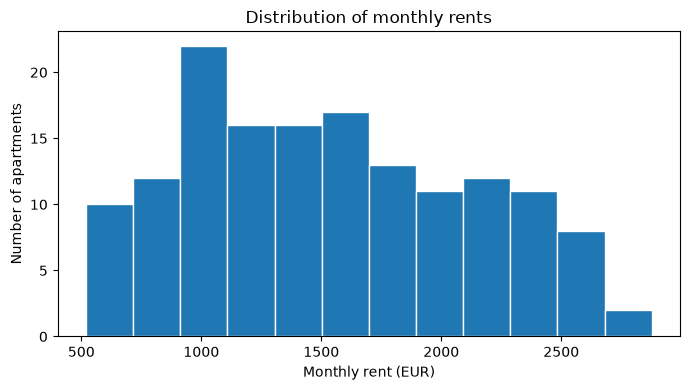

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["monthly_rent_eur"].dropna(), bins=12, edgecolor="white")
ax.set_title("Distribution of monthly rents")
ax.set_xlabel("Monthly rent (EUR)")
ax.set_ylabel("Number of apartments")
plt.tight_layout()
plt.show()

**Mean versus median:** The mean is sensitive to extreme observations; the median is more robust. Inspect both before deciding how to summarize a variable.

Mean monthly rent:   €1534
Median monthly rent: €1493
Minimum / maximum:   €519 / €2877


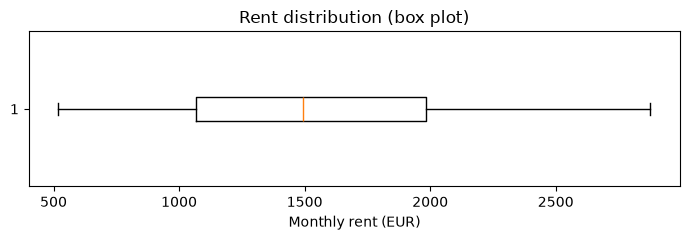

In [8]:
rent = df["monthly_rent_eur"]
print(f"Mean monthly rent:   €{rent.mean():.0f}")
print(f"Median monthly rent: €{rent.median():.0f}")
print(f"Minimum / maximum:   €{rent.min():.0f} / €{rent.max():.0f}")

fig, ax = plt.subplots(figsize=(7, 2.5))
ax.boxplot(rent.dropna().to_numpy(), orientation='horizontal')
ax.set_title("Rent distribution (box plot)")
ax.set_xlabel("Monthly rent (EUR)")
plt.tight_layout()
plt.show()

A **box plot** summarizes the median, quartiles and possible outliers. Points beyond the whiskers are *potential* outliers—not automatically errors. In a real dataset, investigate them before deleting records.

### Exercise 2 — Explore apartment sizes (5 min)

1. Plot a histogram of `area_m2` with **15 bins** and meaningful labels.
2. Print its median and mean.
3. Answer: Does the distribution look symmetric or skewed? Does the choice of bins affect your interpretation?

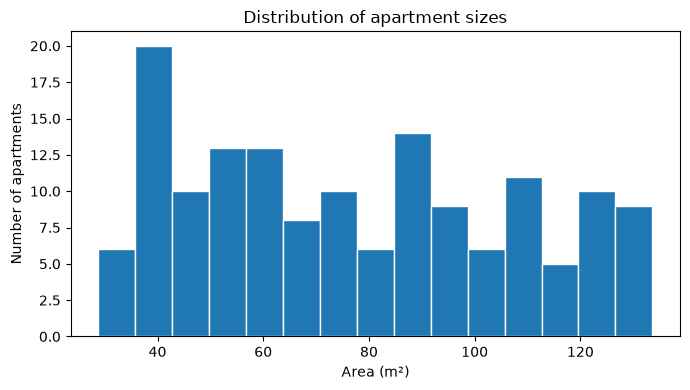

Mean area:   77.1 m²
Median area: 73.9 m²


In [9]:
area = df["area_m2"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(area.dropna(), bins=15, edgecolor="white")
ax.set_title("Distribution of apartment sizes")
ax.set_xlabel("Area (m²)")
ax.set_ylabel("Number of apartments")
plt.tight_layout()
plt.show()

print(f"Mean area:   {area.mean():.1f} m²")
print(f"Median area: {area.median():.1f} m²")

**Your interpretation:**

-The distribution is slightly right-skewed (mean 77.1 m² > median 73.9 m²), and the number of bins changes how it looks: 15 bins look irregular and noisy, while fewer bins show the trend more clearly.

## 3. Explore categories (10 min)

A **bar chart** is usually better than a histogram for categorical variables. Counts show how many observations belong to each category; averages compare numeric outcomes within categories.

Listings by district:


district
Central    23
East       26
North      29
South      32
West       40
Name: count, dtype: int64

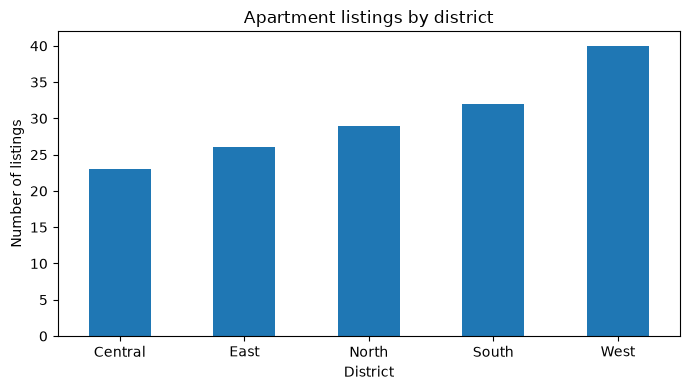

In [10]:
district_counts = df["district"].value_counts().sort_index()
print("Listings by district:")
display(district_counts)

fig, ax = plt.subplots(figsize=(7, 4))
district_counts.plot(kind="bar", ax=ax)
ax.set_title("Apartment listings by district")
ax.set_xlabel("District")
ax.set_ylabel("Number of listings")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

district
East       1318.0
South      1362.0
West       1522.0
North      1615.0
Central    1934.0
Name: monthly_rent_eur, dtype: float64

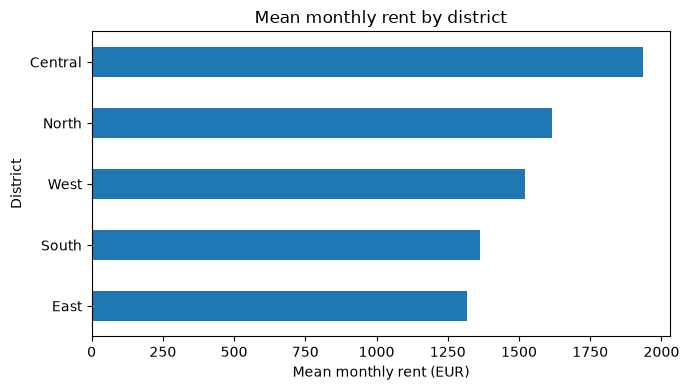

In [11]:
mean_rent_by_district = (
    df.groupby("district")["monthly_rent_eur"]
    .mean()
    .sort_values()
)
display(mean_rent_by_district.round(0))

fig, ax = plt.subplots(figsize=(7, 4))
mean_rent_by_district.plot(kind="barh", ax=ax)
ax.set_title("Mean monthly rent by district")
ax.set_xlabel("Mean monthly rent (EUR)")
ax.set_ylabel("District")
plt.tight_layout()
plt.show()

**Important:** Differences in average rent by district are not automatically caused by district. Apartment size, age, and other characteristics may differ between districts. EDA reveals patterns but does not establish causality.

### Exercise 3 — Is a balcony associated with rent? (4 min)

1. Count listings with and without balconies.
2. Plot mean `monthly_rent_eur` grouped by `balcony`.
3. Why is a simple difference in group means *not enough* to conclude that adding a balcony raises rent?

balcony
no     78
yes    72
Name: count, dtype: int64
balcony
no     1436.0
yes    1640.0
Name: monthly_rent_eur, dtype: float64


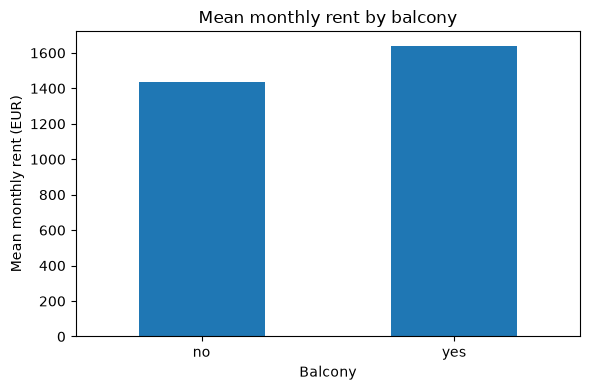

In [12]:
print(df["balcony"].value_counts())

mean_rent_by_balcony = df.groupby("balcony")["monthly_rent_eur"].mean()
print(mean_rent_by_balcony.round(0))

fig, ax = plt.subplots(figsize=(6, 4))
mean_rent_by_balcony.plot(kind="bar", ax=ax)
ax.set_title("Mean monthly rent by balcony")
ax.set_xlabel("Balcony")
ax.set_ylabel("Mean monthly rent (EUR)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Your interpretation:**

- Apartments with a balcony are about 200 € more expensive on average, but they are also larger (80.4 m² vs 74.0 m²), so size or other factors like district could explain the difference: correlation is not causation.

## 4. Investigate relationships between numerical variables (12 min)

A **scatter plot** shows individual observations as points. It can suggest a relationship between two numerical variables. Large values on one axis appearing alongside large values on the other indicates a possible positive association.

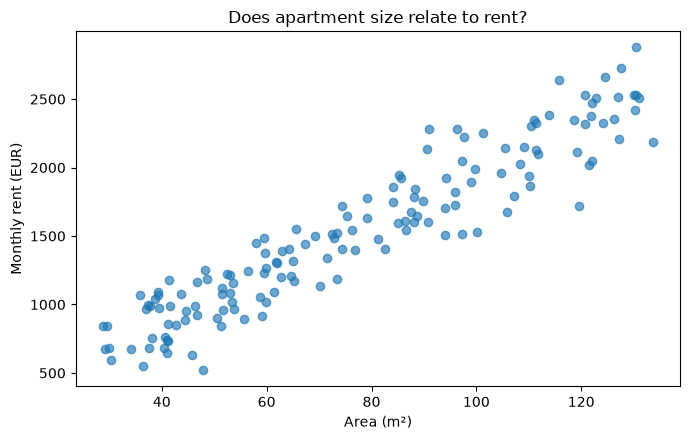

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["area_m2"], df["monthly_rent_eur"], alpha=0.65)
ax.set_title("Does apartment size relate to rent?")
ax.set_xlabel("Area (m²)")
ax.set_ylabel("Monthly rent (EUR)")
plt.tight_layout()
plt.show()

**Correlation** summarizes the *strength and direction of a linear association* between numerical variables. Pearson's correlation lies between -1 and +1. A value near 0 means little **linear** association, not necessarily no relationship at all. Pandas `.corr()` excludes missing pairs by default.

Correlation with monthly rent:


monthly_rent_eur         1.00
area_m2                  0.94
rooms                    0.88
building_age_years      -0.10
distance_to_center_km   -0.33
Name: monthly_rent_eur, dtype: float64

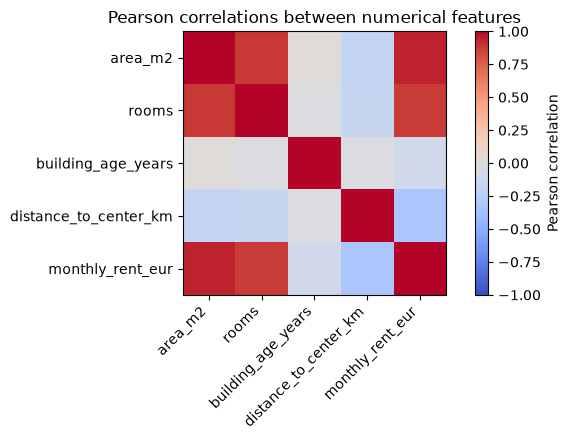

In [14]:
numeric_features = [
    "area_m2", "rooms", "building_age_years",
    "distance_to_center_km", "monthly_rent_eur"
]
corr = df[numeric_features].corr()
print("Correlation with monthly rent:")
display(corr["monthly_rent_eur"].sort_values(ascending=False).round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(numeric_features)), numeric_features, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_features)), numeric_features)
ax.set_title("Pearson correlations between numerical features")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

### Exercise 4 — Distance versus rent (5 min)

1. Make a scatter plot of `distance_to_center_km` against `monthly_rent_eur`.
2. Calculate their Pearson correlation using Pandas.
3. Describe its direction and whether the scatter plot supports your interpretation.
4. Is it appropriate to claim that changing the distance *causes* rent to change? Explain.

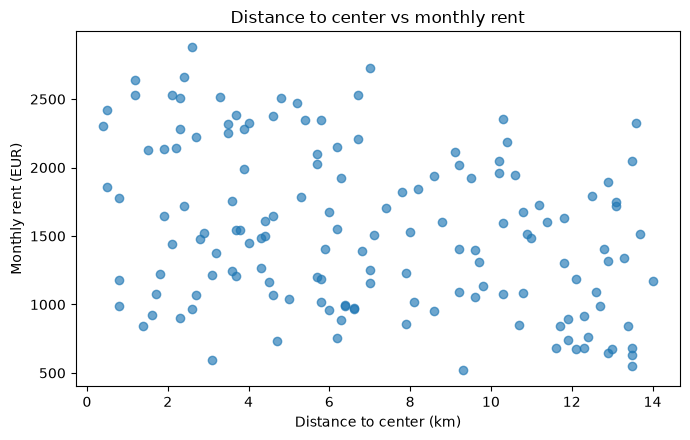

Pearson correlation: -0.33


In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["distance_to_center_km"], df["monthly_rent_eur"], alpha=0.65)
ax.set_title("Distance to center vs monthly rent")
ax.set_xlabel("Distance to center (km)")
ax.set_ylabel("Monthly rent (EUR)")
plt.tight_layout()
plt.show()

corr_dist = df["distance_to_center_km"].corr(df["monthly_rent_eur"])
print(f"Pearson correlation: {corr_dist:.2f}")

**Your interpretation:**

- The correlation is moderately negative (-0.33): rent tends to decrease as distance to the center increases, and the scatter plot shows this downward trend with a lot of spread. We cannot claim causation, because other factors like apartment size (farther apartments are slightly smaller) or district may explain part of the relationship.

## 5. Missing data and suspicious observations (8 min)

Before training models, identify what is missing and whether measurements appear plausible. **Do not delete or replace values yet:** we will study preprocessing systematically in Lab 2.

Missing value counts alone do not show which rows are affected. The examples below locate those rows for inspection.

In [16]:
missing_counts = df.isna().sum()
display(missing_counts[missing_counts > 0].rename("missing_count"))

incomplete_rows = df[df.isna().any(axis=1)]
print(f"Rows with at least one missing value: {len(incomplete_rows)}")
display(incomplete_rows.head(8))

# Simple sanity checks (not automatic error detection)
print("Non-positive area:", (df["area_m2"] <= 0).sum())
print("Non-positive rent:", (df["monthly_rent_eur"] <= 0).sum())
print("Duplicate apartment IDs:", df["apartment_id"].duplicated().sum())

building_age_years       5
distance_to_center_km    2
energy_rating            4
Name: missing_count, dtype: int64

Rows with at least one missing value: 11


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,district,balcony,energy_rating,monthly_rent_eur
7,APT-008,88.3,4,NaN,8.2,North,yes,E,1841
18,APT-019,111.8,4,52.0,5.7,North,yes,NaN,2099
24,APT-025,51.4,3,17.0,NaN,North,no,C,1119
31,APT-032,39.3,2,NaN,9.2,Central,no,C,1089
54,APT-055,121.5,4,38.0,9.2,South,no,NaN,2016
66,APT-067,44.7,3,NaN,8.6,North,no,A,953
89,APT-090,59.8,2,57.0,8.1,East,no,NaN,1018
101,APT-102,97.6,4,NaN,2.7,Central,no,B,2223


Non-positive area: 0
Non-positive rent: 0
Duplicate apartment IDs: 0


### Exercise 5 — Inspect incomplete records (3 min)

1. What percentage of the 150 listings is incomplete (missing at least one field)?
2. Which affected feature would you investigate first, and why?
3. Name one possible risk of simply dropping every incomplete row.

In [17]:
incomplete = df.isna().any(axis=1)
print(f"Incomplete rows: {incomplete.sum()} / {len(df)}")
print(f"Percentage incomplete: {incomplete.mean() * 100:.1f}%")

print(df.isna().sum()[df.isna().sum() > 0])
display(df[incomplete])

Incomplete rows: 11 / 150
Percentage incomplete: 7.3%
building_age_years       5
distance_to_center_km    2
energy_rating            4
dtype: int64


,apartment_id,area_m2,rooms,building_age_years,distance_to_center_km,district,balcony,energy_rating,monthly_rent_eur
7,APT-008,88.3,4,NaN,8.2,North,yes,E,1841
18,APT-019,111.8,4,52.0,5.7,North,yes,NaN,2099
24,APT-025,51.4,3,17.0,NaN,North,no,C,1119
31,APT-032,39.3,2,NaN,9.2,Central,no,C,1089
54,APT-055,121.5,4,38.0,9.2,South,no,NaN,2016
66,APT-067,44.7,3,NaN,8.6,North,no,A,953
89,APT-090,59.8,2,57.0,8.1,East,no,NaN,1018
101,APT-102,97.6,4,NaN,2.7,Central,no,B,2223
114,APT-115,110.3,4,32.0,NaN,West,no,D,1865
124,APT-125,37.0,2,15.0,6.6,South,yes,NaN,965


**Your interpretation:**

- About 7.3% of listings (11/150) are incomplete. I would investigate distance_to_center_km first, because it is clearly related to rent (correlation -0.33), and dropping all incomplete rows would lose data and could bias the sample if the missing values are not random.

## 6. Mini-challenge — Tell a data story (8 min)

Choose **one** question below (or formulate your own), and produce a short evidence-based finding.

- **A.** Are larger apartments more expensive *per square metre*?
- **B.** Does average rent differ between old and new buildings?
- **C.** Is apartment size distributed differently across districts?

Your investigation should include:

1. A **calculation or summary table** supporting your choice.
2. At least **one clearly labeled visualization**.
3. A **3–4 sentence conclusion** describing the pattern, a limitation, and one preprocessing decision needed before model training.

Hints: create `rent_per_m2 = monthly_rent_eur / area_m2`, use `.groupby()`, `.median()`, or a scatter plot. Keep the source CSV unchanged.

,count,median,mean
size_group,,,
<50,36,22.01,22.17
50-75,41,20.66,20.14
75-100,34,19.79,19.95
>100,39,19.21,19.08


Correlation area vs rent per m²: -0.33


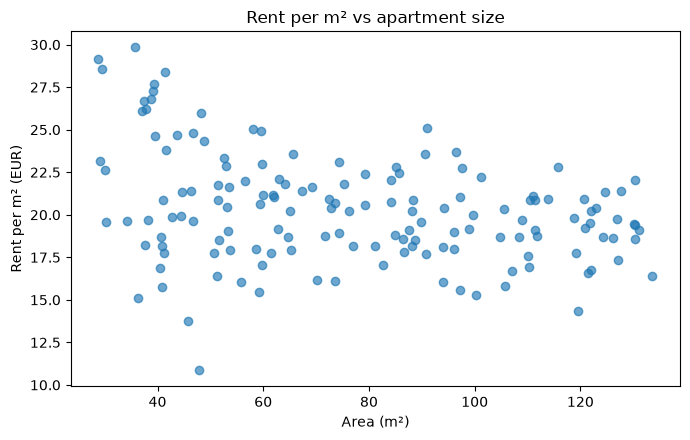

In [18]:
data = df.copy()
data["rent_per_m2"] = data["monthly_rent_eur"] / data["area_m2"]

data["size_group"] = pd.cut(
    data["area_m2"],
    bins=[0, 50, 75, 100, 150],
    labels=["<50", "50-75", "75-100", ">100"]
)
summary = data.groupby("size_group", observed=True)["rent_per_m2"].agg(["count", "median", "mean"])
display(summary.round(2))
print(f"Correlation area vs rent per m²: {data['area_m2'].corr(data['rent_per_m2']):.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(data["area_m2"], data["rent_per_m2"], alpha=0.65)
ax.set_title("Rent per m² vs apartment size")
ax.set_xlabel("Area (m²)")
ax.set_ylabel("Rent per m² (EUR)")
plt.tight_layout()
plt.show()

**Mini-challenge conclusion:**

1. **Question investigated:** Are larger apartments more expensive per square metre?
2. **Observed pattern:** No, the opposite: rent per m² decreases with size, from about 22 €/m² for apartments under 50 m² to about 19 €/m² above 100 m² (correlation -0.33), even though total rent increases.
3. **Limitation or alternative explanation:** This is only an association; district, distance to the center or building age may differ between small and large apartments and explain part of the pattern.
4. **Preprocessing step to consider for Lab 2:** Handle the missing values in `distance_to_center_km`, `building_age_years` and `energy_rating`, and scale the numerical features before training.


## Wrap-up — What should an ML practitioner do next?

You have completed the first stages of a typical workflow:

**CSV data → inspect types and missingness → summarize → visualize → question relationships.**

For the next lab, we will turn this imperfect tabular dataset into data suitable for machine learning. We will consider:

- missing-value strategies;
- encoding categorical variables (`district`, `balcony`, `energy_rating`);
- feature scaling and choosing useful predictors;
- separating training and testing data **before fitting preprocessing transformations** to avoid data leakage.

**Before you finish:** Save your notebook with your plots, TODO solutions, and written interpretations. No model training is required in Lab 1.

**Reflection:** Which two dataset features do you expect would help predict monthly rent? What evidence supports that expectation?